### Building a CNN to classify colon cancer images and other tissue images
Downloading the images and printing meta data.

In [16]:
import medmnist
from medmnist import PathMNIST, INFO
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import pandas as pd
from sklearn.metrics import classification_report



# uses what is fastest available 
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")

info = INFO["pathmnist"]
print(info)

n_classes = len(info["label"])
print(f"Number of classes: {n_classes}")
print(f"Classes: {info['label']}")

{'python_class': 'PathMNIST', 'description': 'The PathMNIST is based on a prior study for predicting survival from colorectal cancer histology slides, providing a dataset (NCT-CRC-HE-100K) of 100,000 non-overlapping image patches from hematoxylin & eosin stained histological images, and a test dataset (CRC-VAL-HE-7K) of 7,180 image patches from a different clinical center. The dataset is comprised of 9 types of tissues, resulting in a multi-class classification task. We resize the source images of 3×224×224 into 3×28×28, and split NCT-CRC-HE-100K into training and validation set with a ratio of 9:1. The CRC-VAL-HE-7K is treated as the test set.', 'url': 'https://zenodo.org/records/10519652/files/pathmnist.npz?download=1', 'MD5': 'a8b06965200029087d5bd730944a56c1', 'url_64': 'https://zenodo.org/records/10519652/files/pathmnist_64.npz?download=1', 'MD5_64': '55aa9c1e0525abe5a6b9d8343a507616', 'url_128': 'https://zenodo.org/records/10519652/files/pathmnist_128.npz?download=1', 'MD5_128': 

- Colorectal adenocarcinoma epithelium is the most common form of colorectal cancer.
- Cancer-associated stroma is cancer-adjacent connective tissue that has been structurally and biologically altered by the nearby tumor.
- Adipose is fatty tissue, made up of fat-storing cells (adipocytes).
- Background is non-tissue slide area, empty space with no biological signal.
- Debris is necrotic or non-viable tissue fragments, not intact functional cells.
- Lymphocytes are immune cells, part of the body's adaptive immune response.
- Mucus is the protective secretion lining the colon's inner surface.
- Smooth muscle is involuntary muscle tissue found in the colon wall, responsible for peristalsis (movement of contents through the digestive tract).
- Normal colon mucosa is the healthy, non-cancerous epithelial lining of the colon — the direct healthy counterpart to adenocarcinoma epithelium.

In [ ]:
# transform just normalizes, resizes, augments, and process images before feeding into model 
transform = transforms.Compose([
    transforms.ToTensor(),
])

# split into test and train
train_dataset_bio = PathMNIST(split="train", download=True, transform=transform)
test_dataset_bio = PathMNIST(split="test", download=True, transform=transform)

print(f"Train size: {len(train_dataset_bio)}, Test size: {len(test_dataset_bio)}")

Train size: 89996, Test size: 7180


Let's look at some examples of the images in this dataset. 

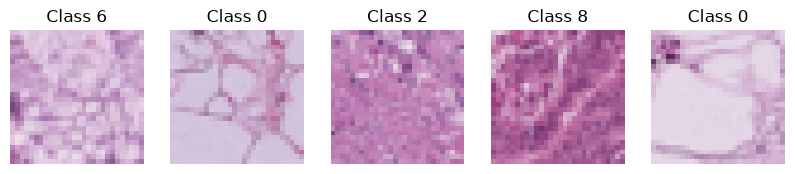

In [ ]:
train_loader_bio = DataLoader(train_dataset_bio, batch_size=64, shuffle=True)

images, labels = next(iter(train_loader_bio))
fig, axs = plt.subplots(1, 5, figsize=(10, 2))
for i in range(5):
    axs[i].imshow(images[i].permute(1, 2, 0))   # PathMNIST images are RGB, so no cmap='gray'
    axs[i].set_title(f"Class {labels[i].item()}")
    axs[i].axis("off")
plt.show()

Let's see how many images in each of the 9 classes.

In [4]:
import numpy as np
labels_array = np.array([label for _, label in train_dataset_bio])
unique, counts = np.unique(labels_array, return_counts=True)
for cls, count in zip(unique, counts):
    print(f"Class {cls}: {count} images")

Class 0: 9366 images
Class 1: 9509 images
Class 2: 10360 images
Class 3: 10401 images
Class 4: 8006 images
Class 5: 12182 images
Class 6: 7886 images
Class 7: 9401 images
Class 8: 12885 images


The CNN class classifies into 9 categories. It has 2 convolution layers, and 2 fully connected layers. Only difference with this model and the test model (Fashion MNIST) is that the input image has 3 channels. 

In [5]:
class HistologyCNN(nn.Module):
    def __init__(self, num_classes=9):
        super(HistologyCNN, self).__init__()
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.fc1 = nn.Linear(32 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

model_bio = HistologyCNN(num_classes=9).to(device)
print(model_bio)

HistologyCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=1568, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=9, bias=True)
)


Train the model across 5 epochs, ~1400 batches per epoch, 64 images per batch.

In [6]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_bio.parameters(), lr=0.001)

num_epochs = 5

for epoch in range(num_epochs):
    model_bio.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader_bio:
        images = images.to(device)
        labels = labels.squeeze().long().to(device)   # fix label shape/dtype for MedMNIST

        outputs = model_bio(images)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    print(f"Epoch {epoch+1}/{num_epochs} — Loss: {epoch_loss:.4f}, Train Accuracy: {epoch_acc:.4f}")

Epoch 1/5 — Loss: 1.0900, Train Accuracy: 0.5912
Epoch 2/5 — Loss: 0.7568, Train Accuracy: 0.7250
Epoch 3/5 — Loss: 0.6615, Train Accuracy: 0.7609
Epoch 4/5 — Loss: 0.5943, Train Accuracy: 0.7860
Epoch 5/5 — Loss: 0.5523, Train Accuracy: 0.8011


Time to evaluate the model on test data, and keep track of all predictions vs true labels for the confusion matrix. 

Test Accuracy: 0.6734


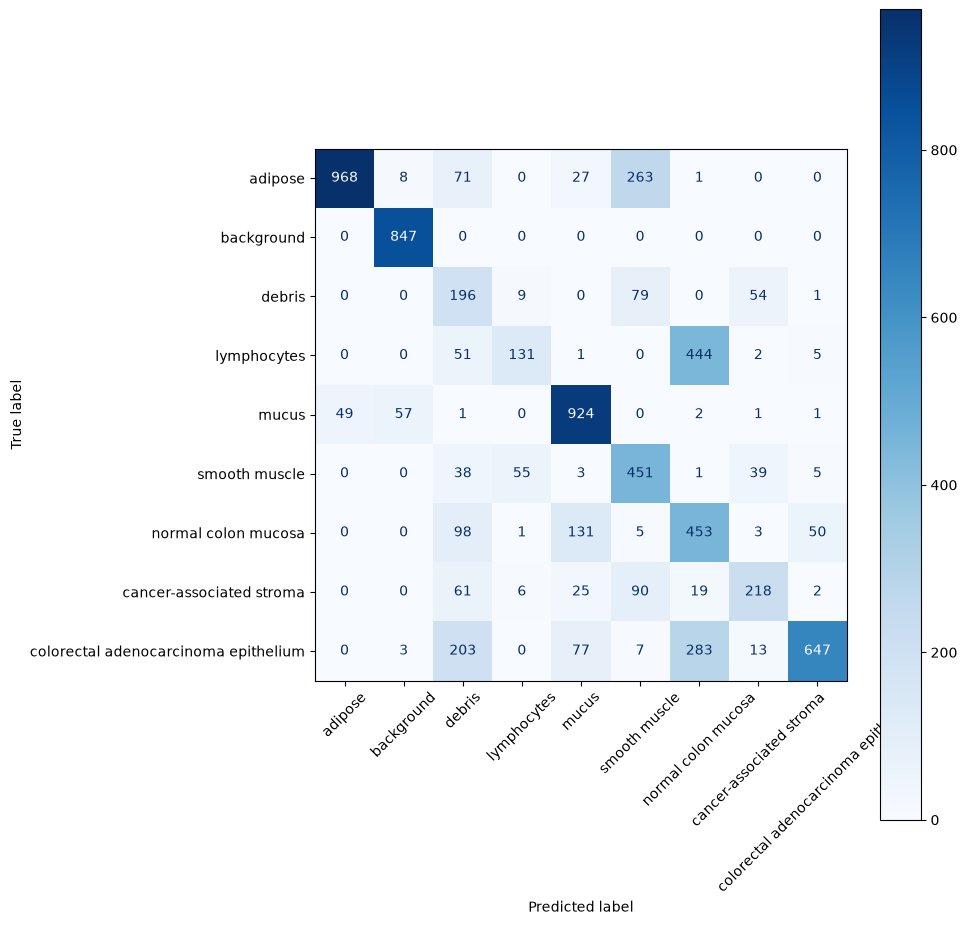

In [ ]:
test_loader_bio = DataLoader(test_dataset_bio, batch_size=64, shuffle=True)

model_bio.eval()
correct = 0
total = 0
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader_bio:
        images = images.to(device)
        labels = labels.squeeze().long().to(device)
        outputs = model_bio(images)
        _, predicted = torch.max(outputs, 1)

        correct += (predicted == labels).sum().item()
        total += labels.size(0)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

test_acc = correct / total
print(f"Test Accuracy: {test_acc:.4f}")

class_names = list(info["label"].values())
cm = confusion_matrix(all_labels, all_preds)

fig, ax = plt.subplots(figsize=(10, 10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, xticks_rotation=45, cmap="Blues")
plt.tight_layout()
plt.show()

The training accuracy was 80.1% after 5 epochs, but the test accuracy was only 67.3%, showing some overfitting. Some contributing factors:
- There was no data augumentation, there could be different orientations, stains, etc in the training not present in test. 
- Simple 2 convolution layer CNN trained from scratch struggles to learn as well as a pre-trained model like ResNet
- Images may be visually similar

Let's see the confusion matrix to see where the mislabeling is happening. The worst predictions are the lymphocytes being confused as normal colon mucosa, and colorectal adenocarcinoma epithelium being confused as normal colon mucosa. The latter is more detrimental, as it is a false negative, and the cancer diagnosis based on this model would be incorrect.  

In [ ]:
cm_df = pd.DataFrame(cm, index=class_names, columns=class_names)
print(cm_df.loc["colorectal adenocarcinoma epithelium", "normal colon mucosa"])  # cancer → predicted normal (false negative)
print(cm_df.loc["normal colon mucosa", "colorectal adenocarcinoma epithelium"])  # normal → predicted cancer (false positive)

283
50


The cancerous tissue is mistaken as normal 283 times and normal is mistaken as cancerous 50 times. The false negatives are much higher than the false positives, which is more dangerous because it leaves the cancer untreated if not investigated further. 

Precision is TP/TP + FP. Out of everything marked as positive, how much were actually positive? Controls false positives. 
Recall is TP/TP + FN. Out of all the real postives, how many were caught? Controls false negatives. 

In [ ]:
print(classification_report(all_labels, all_preds, target_names=class_names))

                                      precision    recall  f1-score   support

                             adipose       0.95      0.72      0.82      1338
                          background       0.93      1.00      0.96       847
                              debris       0.27      0.58      0.37       339
                         lymphocytes       0.65      0.21      0.31       634
                               mucus       0.78      0.89      0.83      1035
                       smooth muscle       0.50      0.76      0.61       592
                 normal colon mucosa       0.38      0.61      0.47       741
            cancer-associated stroma       0.66      0.52      0.58       421
colorectal adenocarcinoma epithelium       0.91      0.52      0.67      1233

                            accuracy                           0.67      7180
                           macro avg       0.67      0.65      0.62      7180
                        weighted avg       0.74      0.67     

The recall for actual cancer cases was 52%, which indicates that 48% of truly positive cases are marked as negative. The cancer-associated stroma is also missed 48% of the time. There weren't as many false positives for the cancer tissue, as 91% of the cases marked cancerous, actually were cancerous. However, the cancer-associated stroma had more false positives, because its precision is 66%. The model is conservative about flagging cancer. 

Debris is the least precise class (27% precision), but has the highest recall (58%) relative to its precision. This means that the model is eager to label images as debris and mislabels them as debris more than it misses real debris images. 

Lymphocytes get missed by their histology images (21% recall). Back in my spatial transcriptomics project, the clustering algorithm was able to classify immune cells by their expression alone. Now, we see that lymphocytes are hard to identify by morphology alone (65% precision, 21% recall). Images that are not lymphocytes get marked as lymphocytes, and images that are get missed. 